# TP 8 - NetworkX and Dijkstra

**Course:** Data structures and algorithms - CPE Lyon, 3IRC, 2025/2026

This notebook follows the last practical session:

1. discover the main objects of **NetworkX** on the Petersen graph;
2. load a weighted graph and display it;
3. implement **Dijkstra's algorithm** with a visited *list*, then with a
   *set*, and compare both with a binary-heap version;
4. prepare the optional **OSMnx** route calculator (separate notebook).

The reusable implementation lives in `src/sda/tp08_networkx`; the notebook
keeps the code visible step by step.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

## 1. The Petersen graph

NetworkX represents a graph as a dictionary of dictionaries.  We build the
Petersen graph from its edge list, then ask the library the questions of the
TD.

In [2]:
from sda.tp07_graphs.examples import PETERSEN_EDGES

G = nx.Graph()
G.add_edges_from(PETERSEN_EDGES)
print(G)
print("vertices:", sorted(G.nodes))
print("edges:", sorted(G.edges))

Graph with 10 nodes and 15 edges
vertices: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
edges: [(1, 3), (1, 4), (2, 4), (2, 5), (3, 5), (6, 1), (6, 7), (6, 10), (7, 2), (7, 8), (8, 3), (8, 9), (9, 4), (9, 10), (10, 5)]


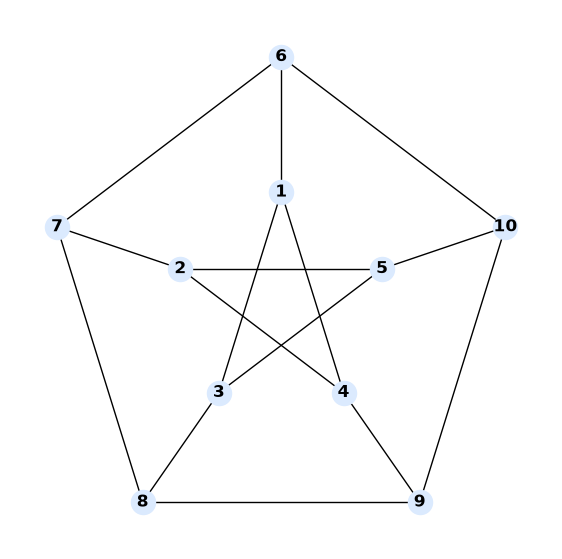

In [3]:
# A drawing close to the usual two-pentagon representation.
pos = {}
for index, vertex in enumerate([6, 7, 8, 9, 10]):
    angle = math.pi / 2 + 2 * math.pi * index / 5
    pos[vertex] = (math.cos(angle), math.sin(angle))
for index, vertex in enumerate([1, 2, 3, 4, 5]):
    angle = math.pi / 2 + 2 * math.pi * index / 5
    pos[vertex] = (0.45 * math.cos(angle), 0.45 * math.sin(angle))

plt.figure(figsize=(7, 7))
nx.draw_networkx(G, pos=pos, with_labels=True, node_color="#dbeafe", font_weight="bold")
plt.axis("off")
plt.show()

### Questions with NetworkX

- Is the graph directed?
- What are its vertices and edges?
- Neighbours of 2, degree of 9?
- Is it regular? Connected?
- Adjacency and incidence matrices.
- Induced subgraph on `{6, 3, 7, 8, 1, 5}`.

In [4]:
print("directed:", G.is_directed())
print("neighbours of 2:", list(G.neighbors(2)))
print("degree of 9:", G.degree[9])
print("degrees:", dict(G.degree))
print("regular:", nx.is_regular(G))
print("connected:", nx.is_connected(G))
print("bipartite:", nx.is_bipartite(G))

directed: False
neighbours of 2: [7, 5, 4]
degree of 9: 3
degrees: {6: 3, 7: 3, 8: 3, 9: 3, 10: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3}
regular: True
connected: True
bipartite: False


In [5]:
adjacency = nx.to_numpy_array(G, nodelist=sorted(G.nodes), dtype=int)
print("adjacency matrix:")
print(adjacency)

incidence = nx.incidence_matrix(G).todense()
print("incidence matrix shape:", incidence.shape)
print("column sums:", np.asarray(incidence).sum(axis=0))

adjacency matrix:
[[0 0 1 1 0 1 0 0 0 0]
 [0 0 0 1 1 0 1 0 0 0]
 [1 0 0 0 1 0 0 1 0 0]
 [1 1 0 0 0 0 0 0 1 0]
 [0 1 1 0 0 0 0 0 0 1]
 [1 0 0 0 0 0 1 0 0 1]
 [0 1 0 0 0 1 0 1 0 0]
 [0 0 1 0 0 0 1 0 1 0]
 [0 0 0 1 0 0 0 1 0 1]
 [0 0 0 0 1 1 0 0 1 0]]


incidence matrix shape: (10, 15)
column sums: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]


induced vertices: [1, 3, 5, 6, 7, 8]
induced edges: [(1, 3), (3, 5), (6, 1), (6, 7), (7, 8), (8, 3)]
degrees: {6: 2, 7: 2, 8: 2, 1: 2, 3: 3, 5: 1}


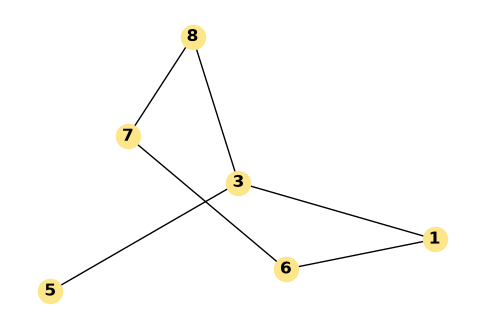

In [6]:
H = G.subgraph([6, 3, 7, 8, 1, 5])
print("induced vertices:", sorted(H.nodes))
print("induced edges:", sorted(H.edges))
print("degrees:", dict(H.degree))

plt.figure(figsize=(6, 4))
nx.draw_networkx(H, with_labels=True, node_color="#fde68a", font_weight="bold")
plt.axis("off")
plt.show()

## 2. A weighted course graph

The fixture in `data/tp08_graph.txt` has 20 vertices, 30 edges, weights
between 1 and 50, and is connected.  It is loaded with the same
`read_multiline_adjlist` function as in the statement.

In [7]:
from sda.tp08_networkx.fixture import load_graph, START, TARGET

weighted = load_graph()
print(weighted)
print("connected:", nx.is_connected(weighted))
print("weight of 0-8:", weighted[0][8])
print("number of edges:", weighted.number_of_edges())

Graph with 20 nodes and 30 edges
connected: True
weight of 0-8: {'weight': 36.0}
number of edges: 30


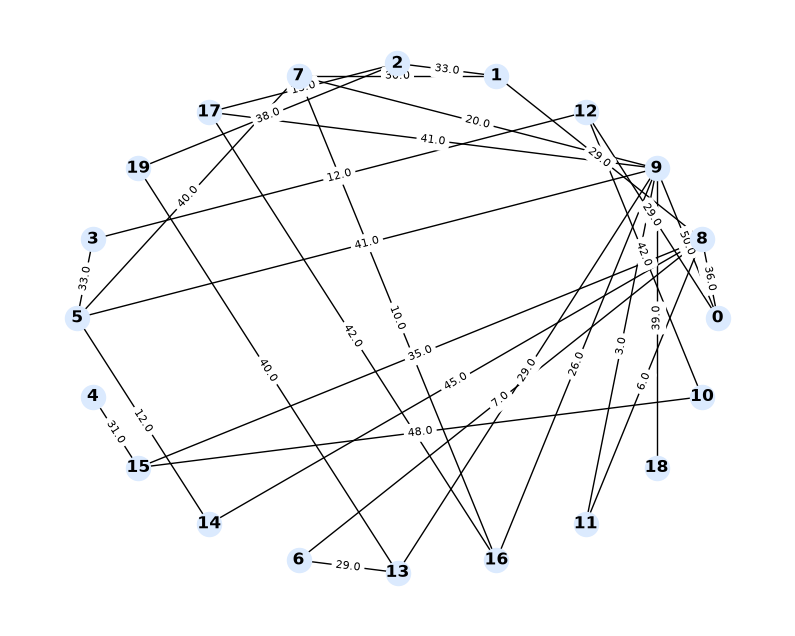

In [8]:
pos = nx.circular_layout(weighted)
plt.figure(figsize=(10, 8))
nx.draw_networkx(weighted, pos=pos, with_labels=True, node_color="#dbeafe", font_weight="bold")
labels = nx.get_edge_attributes(weighted, "weight")
nx.draw_networkx_edge_labels(weighted, pos=pos, edge_labels=labels, font_size=8)
plt.axis("off")
plt.show()

## 3. Dijkstra with a visited list

The algorithm maintains:

- `distances[v]`: best known distance from the source;
- `previous[v]`: predecessor on the best path;
- `visited`: vertices whose distance is final.

At each iteration we select the unvisited vertex with the smallest distance,
then relax its edges.  Keeping `visited` in a **list** makes the membership
test `v in visited` linear: the total cost becomes `O(V^2)` just for these
tests.

In [9]:
def dijkstra1(graph, start, target):
    distances = {start: 0.0}
    previous = {}
    visited = []

    while True:
        candidates = [v for v in distances if v not in visited]
        if not candidates:
            break
        current = min(candidates, key=distances.get)
        if current == target:
            break
        visited.append(current)
        for neighbour, data in graph[current].items():
            if neighbour in visited:
                continue
            weight = data.get("weight", data.get("length", 1))
            candidate = distances[current] + weight
            if candidate < distances.get(neighbour, math.inf):
                distances[neighbour] = candidate
                previous[neighbour] = current

    if target not in distances:
        return math.inf, []
    path = [target]
    while path[-1] != start:
        path.append(previous[path[-1]])
    return distances[target], path[::-1]

In [10]:
distance, path = dijkstra1(weighted, START, TARGET)
print("length:", distance)
print("path:", path)

length: 112.0
path: [0, 8, 6, 13, 19]


## 4. Replacing the list with a set

A `set` gives an `O(1)` membership test.  The minimum search is still linear
in the number of vertices, but the expensive membership tests disappear.  The
result must be identical.

In [11]:
def dijkstra2(graph, start, target):
    distances = {start: 0.0}
    previous = {}
    visited = set()

    while True:
        candidates = [v for v in distances if v not in visited]
        if not candidates:
            break
        current = min(candidates, key=distances.get)
        if current == target:
            break
        visited.add(current)
        for neighbour, data in graph[current].items():
            if neighbour in visited:
                continue
            weight = data.get("weight", data.get("length", 1))
            candidate = distances[current] + weight
            if candidate < distances.get(neighbour, math.inf):
                distances[neighbour] = candidate
                previous[neighbour] = current

    if target not in distances:
        return math.inf, []
    path = [target]
    while path[-1] != start:
        path.append(previous[path[-1]])
    return distances[target], path[::-1]

In [12]:
print("dijkstra1:", dijkstra1(weighted, START, TARGET))
print("dijkstra2:", dijkstra2(weighted, START, TARGET))

dijkstra1: (112.0, [0, 8, 6, 13, 19])
dijkstra2: (112.0, [0, 8, 6, 13, 19])


## 5. A binary heap

With a heap, the minimum extraction and the relaxation of an edge cost
`O(log V)`, for a total of `O((V + E) log V)`.  NetworkX does not offer
decrease-key, so we push a new pair when a distance improves and skip stale
entries when they are popped.

In [13]:
import heapq


def dijkstra_heap(graph, start, target):
    distances = {start: 0.0}
    previous = {}
    queue = [(0.0, start)]
    visited = set()

    while queue:
        distance, current = heapq.heappop(queue)
        if current in visited:
            continue
        visited.add(current)
        if current == target:
            break
        for neighbour, data in graph[current].items():
            if neighbour in visited:
                continue
            weight = data.get("weight", data.get("length", 1))
            candidate = distance + weight
            if candidate < distances.get(neighbour, math.inf):
                distances[neighbour] = candidate
                previous[neighbour] = current
                heapq.heappush(queue, (candidate, neighbour))

    if target not in distances:
        return math.inf, []
    path = [target]
    while path[-1] != start:
        path.append(previous[path[-1]])
    return distances[target], path[::-1]

In [14]:
print("heap:", dijkstra_heap(weighted, START, TARGET))
print("NetworkX:", nx.shortest_path_length(weighted, START, TARGET, weight="weight"))

heap: (112.0, [0, 8, 6, 13, 19])
NetworkX: 112.0


## 6. Timing the three versions

The course graph is tiny, so the difference is small.  On a 400-vertex random
graph the quadratic behaviour of the list membership becomes visible.

In [15]:
def timed(algorithm, graph, start, target):
    begin = time.perf_counter()
    result = algorithm(graph, start, target)
    return result, time.perf_counter() - begin

for algorithm in (dijkstra1, dijkstra2, dijkstra_heap):
    (distance, path), elapsed = timed(algorithm, weighted, START, TARGET)
    print(f"{algorithm.__name__:>13}: {distance:>6} in {elapsed * 1e6:8.1f} us")

    dijkstra1:  112.0 in    151.6 us
    dijkstra2:  112.0 in    100.9 us
dijkstra_heap:  112.0 in     69.4 us


In [16]:
seed = 0
while True:
    large = nx.gnm_random_graph(400, 900, seed=seed)
    if nx.is_connected(large):
        break
    seed += 1
for source, target in large.edges():
    large[source][target]["weight"] = (source * 31 + target * 17) % 50 + 1

print(f"large graph: {large.number_of_nodes()} vertices, {large.number_of_edges()} edges")
print("NetworkX length:", nx.shortest_path_length(large, 0, 399, weight="weight"))
for algorithm in (dijkstra1, dijkstra2, dijkstra_heap):
    (distance, path), elapsed = timed(algorithm, large, 0, 399)
    print(f"{algorithm.__name__:>13}: {distance:>8} in {elapsed * 1e3:8.2f} ms")

large graph: 400 vertices, 900 edges
NetworkX length: 103


    dijkstra1:    103.0 in   231.36 ms
    dijkstra2:    103.0 in    10.21 ms
dijkstra_heap:    103.0 in     1.59 ms


## 7. Conclusion

- NetworkX makes graph construction, inspection and drawing immediate, but
  the exercise asks for the algorithm to be written by hand.
- The **visited list** is correct but adds an `O(V)` test inside the main
  loop.
- The **set** removes this cost; the remaining `O(V^2)` term comes from the
  linear minimum search.
- The **heap** reduces the total cost to `O((V + E) log V)`.
- All three versions return the same shortest path.

The OSMnx application (Lyon street network, geocoding, route and map) is in
`tp08_osmnx_routing.ipynb`, because it needs internet access and the optional
`osmnx` package.